# Data Analysis and Product Statistics: A Deep Dive
This notebook is an investigation into the usage of libraries such as Seaborn, Pandas, and matplotlib to function as data analysis tools for load testing applications

In [65]:
# Load one normalized synthetic dataset for carabiner comparison practice.
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

test_data = pd.read_csv("synthetic_carabiner_test_results.csv")
test_data["test_date"] = pd.to_datetime(test_data["test_date"])
test_data.head()



,test_id,project_code,serial_number,test_date,carabiner_shape,material,gate_type,loading_case,time_s,load_kN,data_source
0,T-001,101,101-PEAR-001,2026-09-01,pear,aluminum,screwgate,axial,0.0,0.00,synthetic_practice_data
1,T-001,101,101-PEAR-001,2026-09-01,pear,aluminum,screwgate,axial,0.5,2.47,synthetic_practice_data
2,T-001,101,101-PEAR-001,2026-09-01,pear,aluminum,screwgate,axial,1.0,4.94,synthetic_practice_data
3,T-001,101,101-PEAR-001,2026-09-01,pear,aluminum,screwgate,axial,1.5,7.41,synthetic_practice_data
4,T-001,101,101-PEAR-001,2026-09-01,pear,aluminum,screwgate,axial,2.0,9.88,synthetic_practice_data


In [66]:
test_data[[
    "test_id", "project_code", "serial_number", "carabiner_shape", "material", "gate_type"
]].drop_duplicates().sort_values("test_id")



,test_id,project_code,serial_number,carabiner_shape,material,gate_type
0,T-001,101,101-PEAR-001,pear,aluminum,screwgate
33,T-002,101,101-PEAR-002,pear,aluminum,screwgate
66,T-003,202,202-OVAL-001,oval,aluminum,nonlocking solid
99,T-004,202,202-OVAL-002,oval,aluminum,nonlocking solid
132,T-005,303,303-HMS-001,hms,aluminum,tripleaction
165,T-006,303,303-HMS-002,hms,aluminum,tripleaction
198,T-007,404,404-OVAL-001,oval,steel,wiregate
231,T-008,404,404-OVAL-002,oval,steel,wiregate


In [67]:
def one_test_stats(data, test_id):
    test = data.loc[data["test_id"].eq(test_id)]
    if test.empty:
        raise ValueError(f"No data found for {test_id}.")
    return test.groupby("loading_case")["load_kN"].max()


def all_test_stats(data):
    return (
        data.groupby(
            ["test_id", "project_code", "serial_number", "carabiner_shape", "material", "gate_type", "loading_case"],
            as_index=False,
        )["load_kN"]
        .max()
        .rename(columns={"load_kN": "peak_load_kN"})
    )


one_test_stats(test_data, "T-001")


loading_case
axial        24.7
crossload     7.4
opengate      6.8
Name: load_kN, dtype: float64

In [68]:
class LoadTestGrapher:
    case_labels = {
        "axial": "Axial Load",
        "crossload": "Cross-load",
        "opengate": "Open-gate",
    }

    def __init__(self, data):
        required_columns = {"test_id", "loading_case", "time_s", "load_kN"}
        missing_columns = required_columns.difference(data.columns)
        if missing_columns:
            raise ValueError(f"Missing required columns: {sorted(missing_columns)}")
        self.data = data.copy()

    def plot(self, hue="carabiner_shape"):
        if hue not in self.data.columns:
            raise ValueError(f"{hue!r} is not a column in the test data.")

        sns.set_theme(style="whitegrid", context="notebook")
        fig, axes = plt.subplots(1, 3, figsize=(17, 5), constrained_layout=True)
        fig.suptitle("Carabiner Load-Test Comparison", fontsize=18, fontweight="bold")

        for axis, (case, label) in zip(axes, self.case_labels.items()):
            case_data = self.data.loc[self.data["loading_case"].eq(case)]
            sns.lineplot(
                data=case_data,
                x="time_s",
                y="load_kN",
                hue=hue,
                units="test_id",
                estimator=None,
                marker="o",
                ax=axis,
            )
            axis.set_title(label, fontweight="bold")
            axis.set_xlabel("Time (s)")
            axis.set_ylabel("Load (kN)")
            axis.legend(title=hue.replace("_", " ").title(), frameon=False)

        return fig, axes



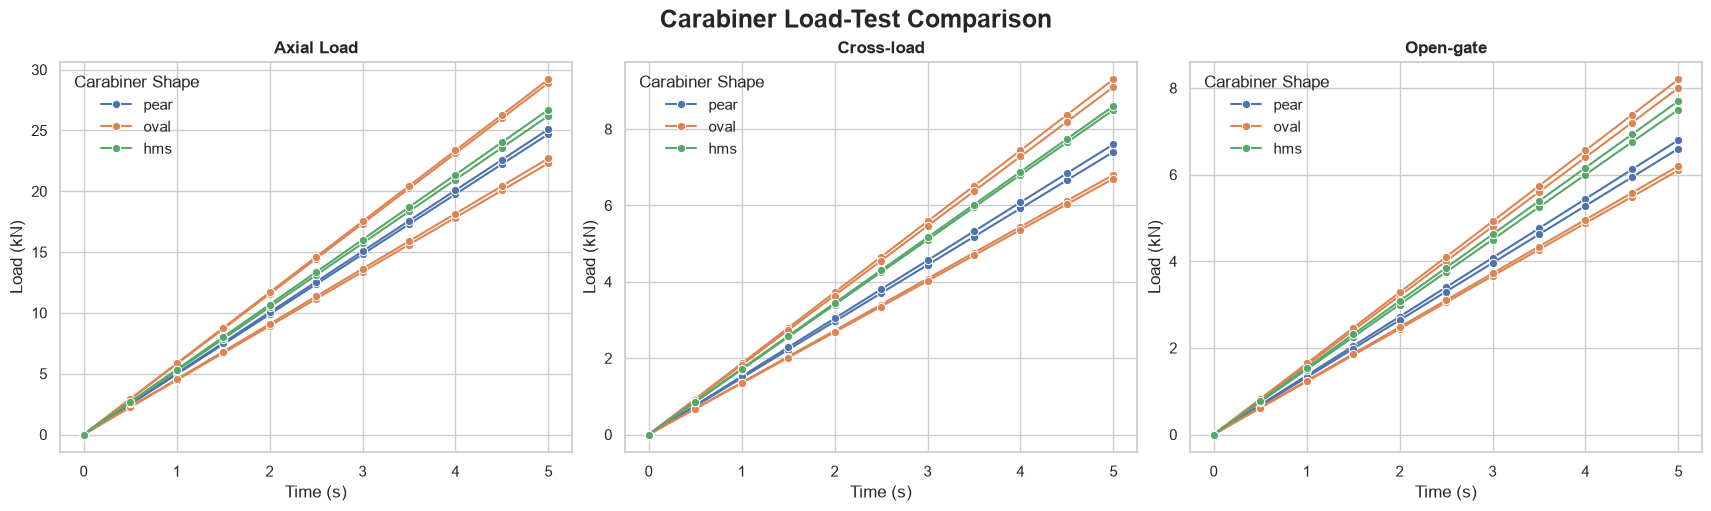

In [69]:
grapher = LoadTestGrapher(test_data)
fig, axes = grapher.plot(hue="carabiner_shape")